# LAB 09 — Bias, Variance and Imbalanced Data
## Overfitting, ROC/AUC, Resampling, SMOTE and Noisy Data on Real Medical Data

## Student Information
- **Name:** Baqar Ali
- **Student ID:** 023-24-0015
- **Section:** : B
- **GitHub:**: https://github.com/baqar360/ML-Lab-Semester-5
- **Kaggle:** : https://www.kaggle.com/baqarali1234
- **Dataset:** Stroke Prediction Dataset (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

### Before You Start
- You already know the models, scaling, splitting and cross-validation from Labs 3-8. This lab does not re-teach them.
- Every task ends with a question about **your own results**. A table or plot without a written interpretation earns no marks.
- Use `SEED = 42` everywhere. **Golden rule:** anything that learns from data (scaler, imputer, resampler, threshold) is learned from the **training data only**.
- Install once if needed: `pip install imbalanced-learn`


---

## Part 0 — Setup and the Data
A hospital wants to flag patients at risk of stroke from routine information. Target: `stroke` (1 = had a stroke, 0 = did not).

**What to do:**
1. Import everything you need (including `imblearn`) and set `SEED = 42`.
2. Load the CSV. Report the shape, the columns with missing values, the value counts of `gender`, and the number of patients with `stroke = 1` and `stroke = 0` (count and %).
3. Clean: remove the identifier column; remove any `gender` category with too few rows to learn or test; apply categorical encoding (`pd.get_dummies`) to the text columns.
4. Split 80/20 with `stratify=y`, `random_state=SEED`. Fill missing numeric values with a median learned from the **train** set only. Make a scaled copy (`StandardScaler` fitted on train) for Logistic Regression.
5. Report the number of stroke cases in the train and in the test set.

In [35]:
# YOUR CODE HERE
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


In [36]:
df=pd.read_csv("data.csv")

In [37]:
# YOUR CODE HERE
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 634.7 KB


In [38]:
df["gender"].value_counts()

gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

In [39]:
print(df["stroke"].value_counts())
print("the patient having stroke in % is ",len((df[df["stroke"]==1]))/len(df)*100)
print("the patient having no stroke in % is ",len((df[df["stroke"]==0]))/len(df)*100)

stroke
0    4861
1     249
Name: count, dtype: int64
the patient having stroke in % is  4.87279843444227
the patient having no stroke in % is  95.12720156555773


In [40]:
df=df.drop(columns=["id"])

In [41]:
df = df[df["gender"]!="Other"]

In [42]:
df["gender"].value_counts()
# Other value removed

gender
Female    2994
Male      2115
Name: count, dtype: int64

In [43]:


#  Separate features and target
X = df.drop(columns=["stroke"])
y = df["stroke"]

#  Find categorical columns in X
cat_cols = X.select_dtypes(include=["object", "category"]).columns

# 4. Apply categorical encoding
X = pd.get_dummies(
    X,
    columns=cat_cols,
    dtype=int,
    drop_first=True
)

C:\Users\HP\AppData\Local\Temp\ipykernel_8604\2741439261.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category"]).columns


In [44]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Set random seed
SEED = 42

# 1. Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=SEED
)

# 2. Find numeric columns
num_cols = X_train.select_dtypes(include="number").columns

# 3. Fill missing numeric values using training medians only
imputer = SimpleImputer(strategy="median")

X_train[num_cols] = imputer.fit_transform(X_train[num_cols])
X_test[num_cols] = imputer.transform(X_test[num_cols])

# 4. Create scaled copies for Logistic Regression
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

In [45]:
print("Training Set:")
print("total training points",len(y_train))
print("No Stroke (0):", (y_train == 0).sum())
print("Stroke (1):", (y_train == 1).sum())

print("\nTesting Set:")
print("total testing points",len(y_test))
print("No Stroke (0):", (y_test == 0).sum())
print("Stroke (1):", (y_test == 1).sum())

Training Set:
total training points 4087
No Stroke (0): 3888
Stroke (1): 199

Testing Set:
total testing points 1022
No Stroke (0): 972
Stroke (1): 50


**Question 0.1:** In 2–3 lines: how imbalanced is the data? Why did we use `stratify=y`, and what could go wrong with only a few stroke cases in the test set?

**Your answer:**
data here is imbalanced because the target column has only 249 cases with stroke 1 and remaining has stroke =1 from 5110
we use stratify =y because we want same amount of case to each class in training and testing
if it is not handle the evaluation metrics not give intended results

---

## Part 1 — The Accuracy Trap
**Objective:** show that a model can have excellent accuracy and still be useless.
1. Build a baseline that always predicts the majority class (`DummyClassifier(strategy='most_frequent')`). Report accuracy.
2. Train a default Logistic Regression on the scaled training data. Report Accuracy, Precision, Recall, F1, ROC AUC and PR AUC (average precision) on the test set, and print the confusion matrix.
3. Write a helper function that takes a model and train/test data and returns these six metrics (you will reuse it all lab).

In [46]:
# YOUR CODE HERE

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

# 1. Create the baseline model
dummy = DummyClassifier(strategy="most_frequent")

# 2. Train the model
dummy.fit(X_train, y_train)

# 3. Predict on test data
y_pred_dummy = dummy.predict(X_test)

# 4. Calculate accuracy
accuracy = accuracy_score(y_test, y_pred_dummy)

print("Baseline Accuracy (%):", accuracy * 100)

Baseline Accuracy (%): 95.10763209393346


In [47]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# 1. Create the default Logistic Regression model
lr = LogisticRegression()

# 2. Train on scaled training data
lr.fit(X_train_scaled, y_train)

# 3. Predict classes and probabilities
y_pred = lr.predict(X_test_scaled)
y_prob = lr.predict_proba(X_test_scaled)[:, 1]

# 4. Calculate evaluation metrics
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("ROC AUC:", roc_auc_score(y_test, y_prob))
print("PR AUC (Average Precision):",
      average_precision_score(y_test, y_prob))

# 5. Print confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.952054794520548
Precision: 1.0
Recall: 0.02
F1 Score: 0.0392156862745098
ROC AUC: 0.8394238683127573
PR AUC (Average Precision): 0.2692194490111673

Confusion Matrix:
[[972   0]
 [ 49   1]]


In [48]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

def evaluate_model(model, X_train, y_train, X_test, y_test):
    # Train the model
    model.fit(X_train, y_train)

    # Predict classes and probabilities
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate the six metrics
    results = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC AUC": roc_auc_score(y_test, y_prob),
        "PR AUC": average_precision_score(y_test, y_prob)
    }

    return results

In [49]:
lr_results = evaluate_model(
    LogisticRegression(random_state=SEED, max_iter=1000),
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

for metric, value in lr_results.items():
    print(f"{metric}: {value:.4f}")

Accuracy: 0.9521
Precision: 1.0000
Recall: 0.0200
F1 Score: 0.0392
ROC AUC: 0.8394
PR AUC: 0.2692


**Question 1.1:** Compare the accuracy of the baseline and of Logistic Regression. What do you conclude?

**Question 1.2:** Look at the confusion matrix and the recall. In the hospital's situation, what does a false negative mean, and which numbers should we trust instead of accuracy?

**Your answer:**

- 1 Both of the models have same accuracy it means logistic regression will always pred every patitent is healthy
- 2 false negative means the patient has stroke and our model predict that the patient is healthy
so our target should be to minimize the fn to increase the recall our main target is to predict to patient who has stroke



---

## Part 2 — Underfitting, Overfitting, Bias and Variance
Use **ROC AUC** (not accuracy) as the score from now on.

### Task 2.1 — Validation curve
For `max_depth` = 1, 2, …, 15 and `None`, record the train ROC AUC and the 5-fold stratified CV ROC AUC (train data only). Plot both curves on one chart (labels, title, legend) and report the best depth by CV AUC.

Best max_depth: 4
Best CV ROC AUC: 0.818


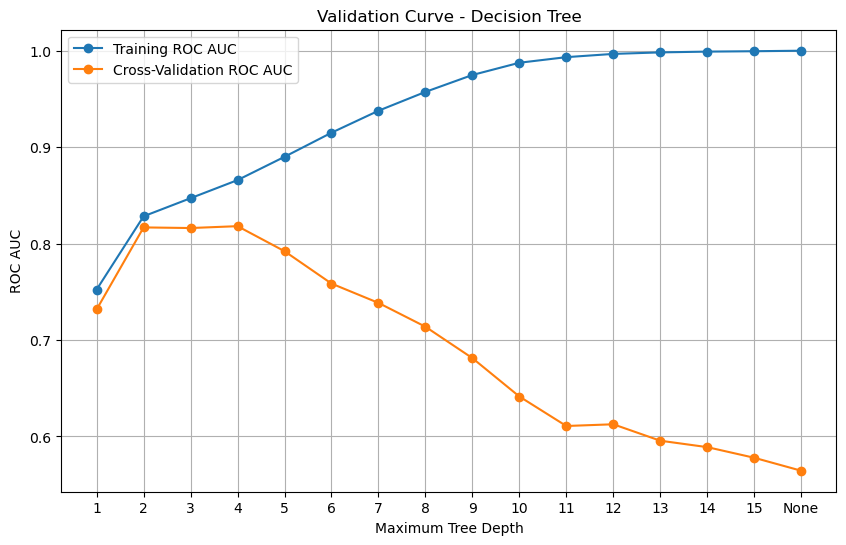

In [50]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import validation_curve, StratifiedKFold
import numpy as np
import matplotlib.pyplot as plt

# Define tree depths
depths = list(range(1, 16)) + [None]

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

# Create Decision Tree model
dt = DecisionTreeClassifier(random_state=SEED)

# Calculate validation curve
train_scores, cv_scores = validation_curve(
    dt,
    X_train,
    y_train,
    param_name="max_depth",
    param_range=depths,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

# Calculate mean ROC AUC
train_mean = train_scores.mean(axis=1)
cv_mean = cv_scores.mean(axis=1)

# Find best depth
best_index = np.argmax(cv_mean)

print("Best max_depth:", depths[best_index])
print("Best CV ROC AUC:", round(cv_mean[best_index], 4))

# Plot validation curve
plt.figure(figsize=(10, 6))

x_values = range(1, 17)

plt.plot(x_values, train_mean, marker='o',
         label="Training ROC AUC")

plt.plot(x_values, cv_mean, marker='o',
         label="Cross-Validation ROC AUC")

plt.xlabel("Maximum Tree Depth")
plt.ylabel("ROC AUC")
plt.title("Validation Curve - Decision Tree")
plt.xticks(x_values, [str(d) for d in depths])
plt.legend()
plt.grid(True)
plt.show()


### Task 2.2 — Learning curves
Use `learning_curve` (`scoring='roc_auc'`, train sizes 20%→100%) for a tree with `max_depth=1` and a tree with `max_depth=None`. Plot train and CV AUC against the number of training rows, side by side.

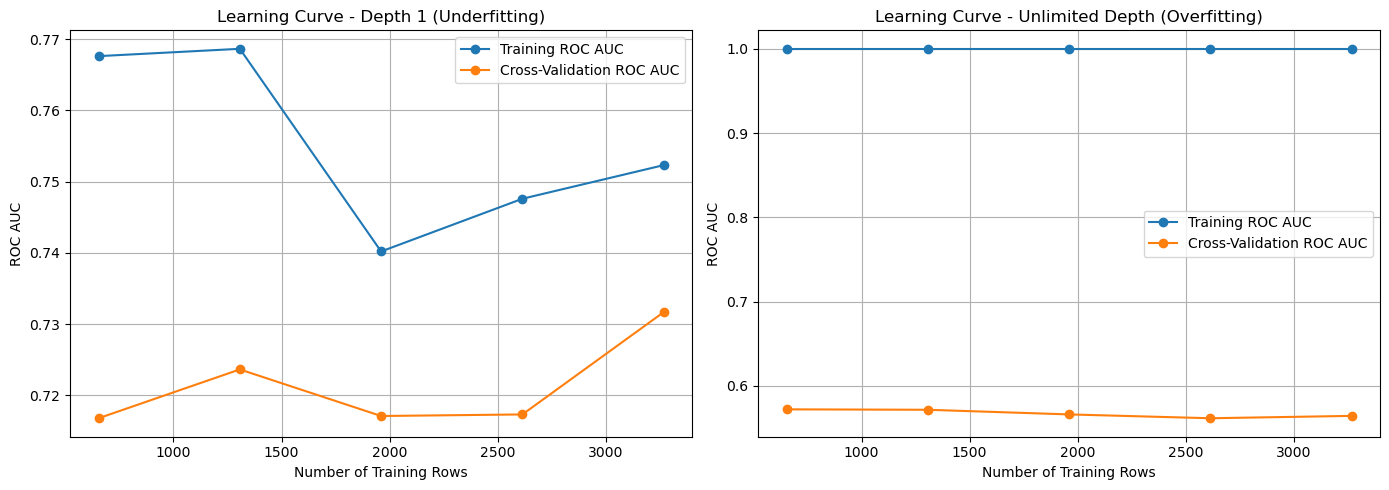

In [51]:
# YOUR CODE HERE

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import learning_curve, StratifiedKFold
import numpy as np
import matplotlib.pyplot as plt

# Define training sizes (20% to 100%)
train_sizes = np.linspace(0.2, 1.0, 5)

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Compare depth 1 and unlimited depth
depths = [1, None]

titles = [
    "Learning Curve - Depth 1 (Underfitting)",
    "Learning Curve - Unlimited Depth (Overfitting)"
]

for ax, depth, title in zip(axes, depths, titles):

    # Calculate learning curve
    sizes, train_scores, cv_scores = learning_curve(
        DecisionTreeClassifier(
            max_depth=depth,
            random_state=SEED
        ),
        X_train,
        y_train,
        train_sizes=train_sizes,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    # Calculate mean ROC AUC
    train_mean = train_scores.mean(axis=1)
    cv_mean = cv_scores.mean(axis=1)

    # Plot training and CV scores
    ax.plot(
        sizes,
        train_mean,
        marker='o',
        label="Training ROC AUC"
    )

    ax.plot(
        sizes,
        cv_mean,
        marker='o',
        label="Cross-Validation ROC AUC"
    )

    ax.set_xlabel("Number of Training Rows")
    ax.set_ylabel("ROC AUC")
    ax.set_title(title)
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()


### Task 2.3 — Measure variance directly
Variance = if the training data changes a little, how much do the predictions change?
1. For `max_depth` = 1, 3 and `None`: draw **40 bootstrap samples** of the train rows (with replacement, same size), fit a tree on each, and collect each tree's predicted stroke probability for every test patient.
2. For every test patient compute the variance of its 40 probabilities, then average over patients. Also report the mean test ROC AUC of the 40 trees and the ROC AUC of the **averaged** prediction.
3. Show the three depths in one table.

*Hints:* `rng.choice(len(X_train), len(X_train), replace=True)` and `X_train.iloc[idx]`; collect an array of shape (40, n_test); `probs.var(axis=0)`.

In [52]:
# YOUR CODE HERE

import numpy as np
import pandas as pd

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score

# Random number generator
rng = np.random.default_rng(SEED)

# Tree depths
depths = [1, 3, None]

# Store final results
results = []

# Repeat experiment for each depth
for depth in depths:

    predictions = []
    auc_scores = []

    # Generate 40 bootstrap samples
    for i in range(40):

        # Random sampling with replacement
        idx = rng.choice(
            len(X_train),
            size=len(X_train),
            replace=True
        )

        X_boot = X_train.iloc[idx]
        y_boot = y_train.iloc[idx]

        # Train Decision Tree
        tree = DecisionTreeClassifier(
            max_depth=depth,
            random_state=SEED
        )

        tree.fit(X_boot, y_boot)

        # Predict stroke probabilities
        probs = tree.predict_proba(X_test)[:, 1]

        predictions.append(probs)

        # Calculate test ROC AUC
        auc = roc_auc_score(y_test, probs)
        auc_scores.append(auc)

    # Convert predictions into NumPy array
    predictions = np.array(predictions)

    # Calculate average prediction variance
    avg_variance = predictions.var(axis=0).mean()

    # Calculate mean AUC of 40 trees
    mean_auc = np.mean(auc_scores)

    # Calculate AUC of averaged predictions
    avg_predictions = predictions.mean(axis=0)

    averaged_auc = roc_auc_score(
        y_test,
        avg_predictions
    )

    # Save results
    results.append({
        "Depth": str(depth),
        "Average Variance": avg_variance,
        "Mean Test AUC": mean_auc,
        "Averaged Prediction AUC": averaged_auc
    })

# Display results table
variance_df = pd.DataFrame(results)

print("Variance Measurement Results:")
display(variance_df.round(4))


Variance Measurement Results:


,Depth,Average Variance,Mean Test AUC,Averaged Prediction AUC
0,1,0.0007,0.7623,0.8132
1,3,0.0017,0.7964,0.8343
2,None,0.0420,0.5552,0.7566


**Question 2.1:** From the validation curve: which depths underfit, which overfit, and which depth would you choose? Quote train and CV AUC for one depth in each zone.

**Question 2.2:** From the learning curves: how can you tell high bias from high variance? Will adding more training rows fix either one?

**Question 2.3:** From the variance table: how does variance change with depth? What happens to the AUC of the averaged prediction compared with the single trees? Link this to what Random Forest does (Lab 4).

**Question 2.4:** In your own words: what is the bias-variance trade-off, and where do depth 1, depth 3 and depth None sit?

**Your answer:**


- 2.1) Depth 1 shows underfitting because the model is too simple to learn complex patterns. Its training ROC AUC is approximately 0.752 and CV ROC AUC is approximately 0.732.

Depths 2 to 4 provide a good balance between training and validation performance. Depth 4 gives the highest CV ROC AUC of approximately 0.818, so I would choose max_depth=4.

Depths 5 to None show overfitting because training performance increases while cross-validation performance decreases. For example, at unlimited depth, training ROC AUC is approximately 1.000 while CV ROC AUC is approximately 0.565.

Therefore, max_depth=4 is the best choice because it provides the best generalization performance.

- 2.2) **Answer:**

High bias can be identified when both training and validation scores are relatively low and close to each other, as shown by the Decision Tree with max_depth=1.

High variance can be identified when the training score is very high but the validation score is much lower, as shown by the unlimited-depth Decision Tree.

Adding more training data may help reduce high variance, but in our experiment, the validation score of the unlimited-depth tree did not improve significantly. Adding more data does not necessarily fix high bias. For high bias, we need a more complex model that can learn better patterns.
- 2.3) **Answer:**

As the depth of the Decision Tree increases, prediction variance also increases. Depth 1 has an average variance of 0.0007, depth 3 has 0.0017, and unlimited depth has the highest variance of 0.0420. This shows that deeper trees are more sensitive to changes in training data.

The AUC of averaged predictions is higher than the mean AUC of individual trees. For depth 1, it improves from 0.7623 to 0.8132. For depth 3, it improves from 0.7964 to 0.8343. For unlimited depth, it improves from 0.5552 to 0.7566.

This is similar to Random Forest, which combines predictions from multiple Decision Trees to reduce variance, produce more stable predictions and improve generalization on unseen data.

- 2.4) **Answer:**

The bias-variance trade-off means finding the right balance between a model that is too simple and a model that is too complex.

- **Depth 1:** Has high bias and low variance because the model is too simple to learn complex patterns.
- **Depth 3:** Provides a better balance between bias and variance because it learns useful patterns without becoming too complex.
- **Depth None:** Has low training error but high variance because it memorizes the training data and performs poorly on unseen data.

Therefore, choosing an appropriate tree depth helps achieve better generalization and prediction performance.



---

## Part 3 — ROC, AUC, Precision-Recall and Thresholds
### Task 3.1 — Compare models with curves
1. Train Logistic Regression (scaled), Decision Tree (`max_depth=3`) and Random Forest (200 trees, `min_samples_leaf=5`, `random_state=SEED`) on the original training data.
2. Draw the ROC curves of the three models on one chart (AUC in the legend, random-guessing diagonal).
3. Draw the Precision-Recall curves on a second chart. Add a horizontal **no-skill line** (the stroke rate) and put the average precision in the legend.

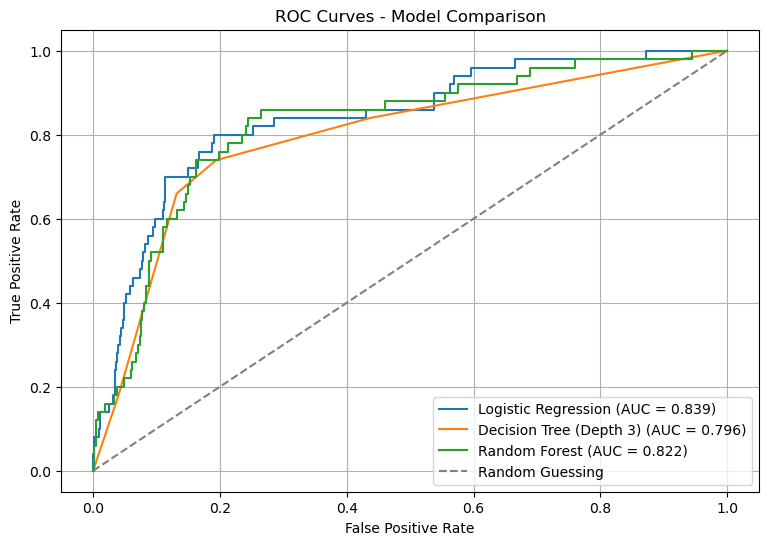

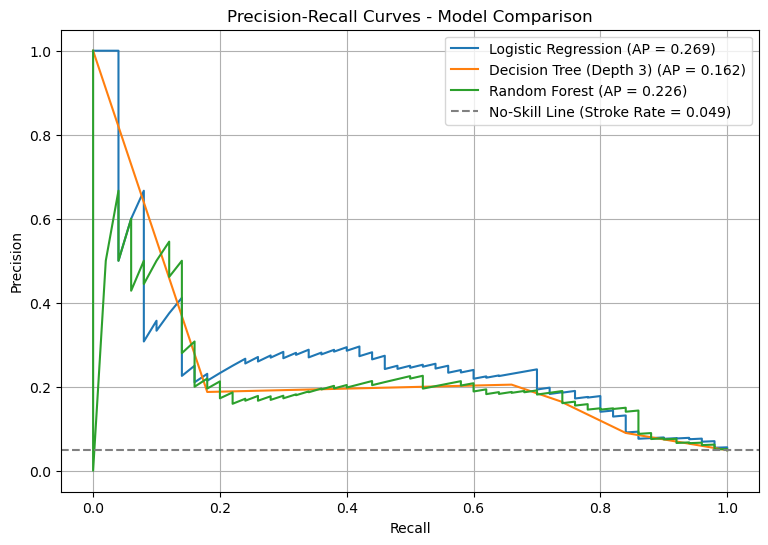

In [53]:
# YOUR CODE HERE

import matplotlib.pyplot as plt
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# --------------------------------
# 1. Train the three models
# --------------------------------

# Logistic Regression (scaled data)
lr = LogisticRegression(
    max_iter=1000,
    random_state=SEED
)

lr.fit(X_train_scaled, y_train)

# Decision Tree (original data)
dt = DecisionTreeClassifier(
    max_depth=3,
    random_state=SEED
)

dt.fit(X_train, y_train)

# Random Forest (original data)
rf = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED,
    n_jobs=-1
)

rf.fit(X_train, y_train)


# --------------------------------
# 2. Get prediction probabilities
# --------------------------------

lr_probs = lr.predict_proba(X_test_scaled)[:, 1]
dt_probs = dt.predict_proba(X_test)[:, 1]
rf_probs = rf.predict_proba(X_test)[:, 1]

models = {
    "Logistic Regression": lr_probs,
    "Decision Tree (Depth 3)": dt_probs,
    "Random Forest": rf_probs
}


# --------------------------------
# 3. Plot ROC Curves
# --------------------------------

plt.figure(figsize=(9, 6))

for name, probs in models.items():

    fpr, tpr, thresholds = roc_curve(y_test, probs)

    auc_score = roc_auc_score(y_test, probs)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

# Random guessing diagonal
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Guessing"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Model Comparison")
plt.legend()
plt.grid(True)
plt.show()


# --------------------------------
# 4. Plot Precision-Recall Curves
# --------------------------------

plt.figure(figsize=(9, 6))

for name, probs in models.items():

    precision, recall, thresholds = precision_recall_curve(
        y_test,
        probs
    )

    ap_score = average_precision_score(y_test, probs)

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP = {ap_score:.3f})"
    )

# No-skill baseline (stroke rate)
stroke_rate = y_test.mean()

plt.axhline(
    y=stroke_rate,
    linestyle="--",
    color="gray",
    label=f"No-Skill Line (Stroke Rate = {stroke_rate:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves - Model Comparison")
plt.legend()
plt.grid(True)
plt.show()


### Task 3.2 — Choose a decision threshold
The hospital wants to catch **at least 80%** of strokes.
1. Using **only the training data**, get out-of-fold probabilities for Logistic Regression (`cross_val_predict(..., method='predict_proba')`), then find the highest threshold that gives recall ≥ 0.80 on them.
2. Apply that threshold to the **test** probabilities. Report test recall, precision, the confusion matrix, how many patients are flagged and how many are false alarms.

In [54]:
# YOUR CODE HERE

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import (
    precision_recall_curve,
    recall_score,
    precision_score,
    confusion_matrix
)

# ---------------------------------------
# 1. Define Logistic Regression model
# ---------------------------------------

lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        random_state=SEED
    )
)

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

# ---------------------------------------
# 2. Get out-of-fold probabilities
#    Using training data ONLY
# ---------------------------------------

oof_probs = cross_val_predict(
    lr_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# ---------------------------------------
# 3. Find highest threshold
#    that achieves recall >= 0.80
# ---------------------------------------

precision, recall, thresholds = precision_recall_curve(
    y_train,
    oof_probs
)

target_recall = 0.80

valid_indices = np.where(recall[:-1] >= target_recall)[0]

if len(valid_indices) == 0:
    raise ValueError("No threshold achieves recall >= 0.80")

best_index = valid_indices[-1]
best_threshold = thresholds[best_index]

print("Selected Threshold:", round(best_threshold, 4))
print("OOF Recall:", round(recall[best_index], 4))

# ---------------------------------------
# 4. Fit model on full training data
#    and predict test probabilities
# ---------------------------------------

lr_model.fit(X_train, y_train)

test_probs = lr_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
test_predictions = (
    test_probs >= best_threshold
).astype(int)

# ---------------------------------------
# 5. Calculate test performance
# ---------------------------------------

test_recall = recall_score(
    y_test,
    test_predictions,
    zero_division=0
)

test_precision = precision_score(
    y_test,
    test_predictions,
    zero_division=0
)

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

# Number of patients flagged
flagged = np.sum(test_predictions)

# Number of false alarms
false_alarms = fp

# ---------------------------------------
# 6. Display results
# ---------------------------------------

print("\nTEST RESULTS")
print("-----------------------------")

print("Test Recall:", round(test_recall, 4))
print("Test Precision:", round(test_precision, 4))

print("\nConfusion Matrix:")
print(cm)

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print("\nTotal Patients Flagged:", flagged)
print("Number of False Alarms:", false_alarms)


Selected Threshold: 0.0509
OOF Recall: 0.804

TEST RESULTS
-----------------------------
Test Recall: 0.82
Test Precision: 0.1353

Confusion Matrix:
[[710 262]
 [  9  41]]

True Negatives: 710
False Positives: 262
False Negatives: 9
True Positives: 41

Total Patients Flagged: 303
Number of False Alarms: 262


**Question 3.1:** In Part 1 the recall was very low, yet the ROC AUC of Logistic Regression is far above 0.5. How can both be true? What does AUC measure, and what does the 0.5 threshold have to do with it?

**Question 3.2:** Which curve is more informative for this data — ROC or Precision-Recall — and why? Use the no-skill line in your answer.

**Question 3.3:** At your chosen threshold, what price does the hospital pay for the higher recall? Is it acceptable? Argue both sides in 3–4 lines.

**Your answer:**



---

## Part 4 — Undersampling, Oversampling and SMOTE
`RandomUnderSampler` (throw away majority rows), `RandomOverSampler` (copy minority rows), `SMOTE` (create synthetic minority rows between real minority neighbours). Another option needs no resampling: `class_weight='balanced'`.

### Task 4.1 — Compare the methods
1. For Logistic Regression (scaled data) and Random Forest (same settings as Part 3) train with: no resampling, `class_weight='balanced'`, random undersampling, random oversampling and SMOTE. **Resample the train set only.**
2. Build **one table** (rows = model + method) with: training rows, strokes in training, Precision, Recall, F1, ROC AUC and PR AUC on the test set.

*Hints:* `from imblearn.over_sampling import SMOTE, RandomOverSampler`; `from imblearn.under_sampling import RandomUnderSampler`; `X_res, y_res = SMOTE(random_state=SEED).fit_resample(X_train, y_train)`. Logistic Regression uses the scaled data, Random Forest the original data.

In [ ]:
# YOUR CODE HERE


### Task 4.2 — The classic mistake
1. Apply SMOTE to **all** the data first (train + test together), **then** split 80/20, train a Random Forest and evaluate. This is the wrong order.
2. Put its metrics next to the correct SMOTE-after-split result from Task 4.1 in a two-row table.

In [ ]:
# YOUR CODE HERE


**Question 4.1:** For Logistic Regression, what changed after resampling and what did NOT change? Compare Recall, Precision and ROC AUC across the methods and explain why.

**Question 4.2:** Did Random Forest react in the same way? Describe one clear difference and give one possible reason.

**Question 4.3:** Compare the wrong-order result with the correct one. Why are the wrong-order numbers so good, and why can they not be trusted? Explain what leaks from where.

**Question 4.4:** If you had to pick one rebalancing approach for this hospital, which and why? Consider simplicity and cost.

**Your answer:**



---

## Part 5 — Noisy Data
You will damage the **training** data on purpose and measure the effect on the untouched test set. Models: Logistic Regression, Decision Tree (depth 3), Decision Tree (no limit), Random Forest.

### Task 5.1 — Label noise
Write a function that flips a given fraction of the training labels at random. For fractions 0, 0.05, 0.10, 0.20 train each model on the noisy labels and record the test ROC AUC. Repeat 5 times with different flips and average (1 repeat for fraction 0). Show a table (rows = fraction, columns = models) and a line plot.

In [ ]:
# YOUR CODE HERE


### Task 5.2 — Feature noise
Add Gaussian noise to the **train** values of `age`, `avg_glucose_level` and `bmi`: `noise = random normal × (column std) × level`. Levels 0, 0.5, 1, 2; five repeats; test set untouched. Same kind of table and plot. (If you scale for Logistic Regression, fit the scaler on the noisy training data.)

In [ ]:
# YOUR CODE HERE


### Task 5.3 — SMOTE and noisy labels
Flip 10% of the training labels (3 different random draws). For Logistic Regression and Random Forest compare **PR AUC and ROC AUC with and without SMOTE** (SMOTE applied after the noise is added).

In [ ]:
# YOUR CODE HERE


**Question 5.1:** Which model is most damaged by noise and which is most stable? Quote numbers at the highest noise level and explain using what you learned in Part 2.

**Question 5.2:** Which hurts more here — label noise or feature noise of a comparable level? Give a short reason.

**Question 5.3:** What did SMOTE do to each model when the labels were noisy? Explain why SMOTE can amplify label noise.

**Your answer:**



---

## Part 6 — Final Decision and Conclusion
1. Choose your final approach for the hospital (model + rebalancing method or threshold). Build a final table on the test set comparing the default threshold 0.5 with your choice: Precision, Recall, F1, number of false alarms and number of missed strokes.
2. Write an **Executive Summary** (6–8 lines): what you chose, its recall and precision with numbers, the price paid, how you avoided leakage, and one limitation (think about only 50 stroke patients in the test set, and about how the threshold was chosen).

In [ ]:
# YOUR CODE HERE


**Executive Summary**

*Your summary here.*


**Final Reflection:** (a) What was the most surprising result in this lab? (b) If you had one more hour, what would you try next?

**Your answer:**

